# Wealth, longevity & carbon — analysis for the 9-slide deck
**Companion to `Wealth_Longevity_Carbon_Concise.pptx` · BUDT704**

The nine numbered sections follow the slides in presentation order. Each section
contains the calculations behind its claims, its chart where applicable, and a
short interpretation. All observations come from **worlddata.csv**, which is
not included in the repository because it exceeds GitHub's 100 MB file limit.

**Run all cells from top to bottom.** Obtain `worlddata.csv` from the project
owner and place it beside the notebook (or in the documented data folder). The code
also finds the CSV in `../All Dataset for Python/` or `All Dataset for Python/`.
In Google Colab, upload the CSV when prompted. Required packages: pandas, numpy,
scipy, matplotlib and scikit-learn (see `requirements.txt`). Randomized steps
use the fixed seed `704`; results can still vary across library versions or platforms.

Charts, samples, predictions and audit tables are written to
`outputs/concise_analysis/`. Saved cell outputs show the executed analysis;
running the notebook recomputes them from the CSV. The original notebook and
presentation outputs are preserved. AI assisted with code and slides.

## Slide 1 — Wealth, longevity & carbon
**Question:** Can economies live longer without emitting more?

Load the source, select indicators by name, reject duplicate keys and exclude
33 overlapping regional/income aggregates. Select the latest year with at least
150 observations for every core variable: **2011**. Use **182 economies** for
the descriptive comparison and **171 complete cases** for modeling. Missing
observations stay missing; no zeros or external data are added. Economies include
territories, and each economy has equal weight unless stated otherwise.

Income is GDP per person in constant 2011 PPP international dollars. The model's
six predictors are income, CO₂ per person, sanitation, water, health spending
as a share of GDP, and urbanization.

In [1]:
from pathlib import Path
import hashlib, json, platform, random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
SEED = 704
random.seed(SEED)
np.random.seed(SEED)
OUT = Path('outputs') / 'concise_analysis'; OUT.mkdir(parents=True, exist_ok=True)
paths = [Path('worlddata.csv'),Path('../All Dataset for Python/worlddata.csv'),Path('All Dataset for Python/worlddata.csv'),Path('/content/worlddata.csv')]
DATA = next((p for p in paths if p.exists()), None)
if DATA is None:
    try:
        from google.colab import files
        files.upload()
        DATA = Path('worlddata.csv')
    except ImportError:
        raise FileNotFoundError('Place worlddata.csv next to this notebook.')
raw = pd.read_csv(DATA)
assert set(raw.columns) == {'CountryName','CountryCode','IndicatorName','IndicatorCode','Year','Value'}
print('Source:', DATA, '\nShape:', raw.shape, '\nYears:', raw.Year.min(), '-', raw.Year.max())
print('Indicators:', raw.IndicatorName.nunique(), '| Entities:', raw.CountryCode.nunique())
print('SHA256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
print('Versions:', platform.python_version(), pd.__version__, np.__version__, sklearn.__version__)
plt.rcParams.update({'figure.figsize':(10,5),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','axes.labelcolor':'#24364B','text.color':'#24364B','savefig.facecolor':'white'})
TEAL='#008C95'; CORAL='#E87455'; NAVY='#142B49'
def chart(name):
    plt.tight_layout(); plt.savefig(OUT/f'{name}.png',dpi=170,bbox_inches='tight'); plt.show()

Source: ../All Dataset for Python/worlddata.csv 
Shape: (5656458, 6) 
Years: 1960 - 2015
Indicators: 1344 | Entities: 247
SHA256: b5df3009c9a3e0b863940d5a08c8d9240cd07a3e6542f6a8de929de188f476ed
Versions: 3.14.0 3.0.6 2.4.0 1.9.1


In [2]:
INDICATORS = {
 'Life expectancy at birth, total (years)':'life',
 'GDP per capita, PPP (constant 2011 international $)':'gdp',
 'CO2 emissions (metric tons per capita)':'co2',
 'Improved sanitation facilities (% of population with access)':'sanitation',
 'Improved water source (% of population with access)':'water',
 'Health expenditure, total (% of GDP)':'health',
 'Urban population (% of total)':'urban',
 'Population, total':'population'}
AGGREGATES = 'ARB CSS CEB EAS EAP EMU ECS ECA EUU FCS HPC HIC NOC OEC LCN LAC LDC LMY LIC LMC MEA MNA MIC NAC OED OSS PSS SST SAS SSF SSA UMC WLD'.split()
assert set(INDICATORS).issubset(set(raw.IndicatorName))
selected = raw[raw.IndicatorName.isin(INDICATORS)].copy()
keys = ['CountryCode','Year','IndicatorName']
assert not selected.duplicated(keys).any(), 'Resolve duplicate economy-year-indicator keys first.'
raw[raw.CountryCode.isin(AGGREGATES)][['CountryCode','CountryName']].drop_duplicates().to_csv(OUT/'excluded_aggregates.csv',index=False)
selected = selected[~selected.CountryCode.isin(AGGREGATES)]
wide = selected.pivot(index=['CountryName','CountryCode','Year'], columns='IndicatorName',values='Value').rename(columns=INDICATORS).reset_index()
features = ['gdp','co2','sanitation','water','health','urban']
coverage = wide.groupby('Year')[['life']+features].count()
print('Coverage in recent years:'); print(coverage.loc[2008:2015].to_string())
coverage.to_csv(OUT/'coverage_by_year.csv')
# Latest year with at least 150 observed economies for EVERY core variable.
valid_years = coverage.index[(coverage[['life']+features]>=150).all(axis=1)]
YEAR = int(valid_years.max())
snap = wide[wide.Year.eq(YEAR)].copy()
missing = snap[['life']+features].isna().sum().sort_values(ascending=False)
print('Common comparison year:',YEAR, '| Snapshot rows:',len(snap))
print('Missing by variable:'); print(missing.to_string())
assert (snap.gdp.dropna()>0).all()
assert (snap.co2.dropna()>=0).all()
assert snap.life.dropna().between(0,120).all()
for col in ['sanitation','water','urban']: assert snap[col].dropna().between(0,100).all()
# Separate descriptive sample from the more restrictive model sample.
pair = snap.dropna(subset=['life','gdp','co2']).copy()
complete = snap.dropna(subset=['life']+features).copy()
complete['log_gdp'] = np.log(complete.gdp)
complete['log_co2'] = np.log1p(complete.co2)
print('Descriptive sample:',len(pair),'| Complete modeling sample:',len(complete))
print('Missingness comparison, medians (not a representativeness test):')
snap['included'] = snap.CountryCode.isin(complete.CountryCode)
print(snap.groupby('included')[['life','gdp','co2']].agg(['count','median']).round(2).to_string())
snap.to_csv(OUT/'snapshot_with_missingness.csv',index=False)
complete.to_csv(OUT/'model_sample.csv',index=False)

Coverage in recent years:
IndicatorName  life  gdp  co2  sanitation  water  health  urban
Year                                                           
2008            202  188  199         194    195     188    212
2009            202  188  199         194    195     188    212
2010            200  188  199         194    195     188    212
2011            201  192  199         195    196     188    212
2012            198  187    0         193    194     188    212
2013            198  187    0         192    191     188    212
2014              0  179    0         191    191       0    212
2015              0    0    0         190    190       0      0
Common comparison year: 2011 | Snapshot rows: 214
Missing by variable:
IndicatorName
health        26
gdp           22
sanitation    19
water         18
co2           15
life          13
urban          2
Descriptive sample: 182 | Complete modeling sample: 171
Missingness comparison, medians (not a representativeness test):
Indicator

## Slide 2 — Higher income, longer lives
**Slide finding: income–longevity rank correlation = 0.842.**

Compare the same 182 economies in 2011. A logarithmic income axis gives equal
space to equal proportional changes. Color represents log(1 + CO₂ per person),
and the fitted log-income curve summarizes association. Vertical spread shows
that similar incomes can accompany different life expectancies.

Spearman income/longevity: 0.842 (descriptive association)


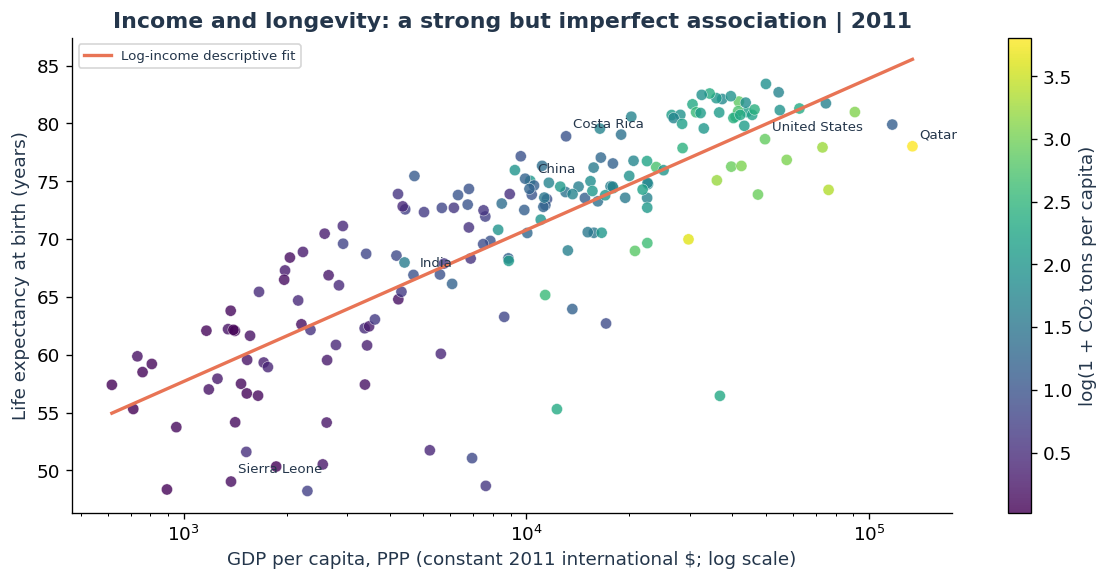

In [3]:
rho,pval=spearmanr(pair.gdp,pair.life)
print('Spearman income/longevity:',round(rho,3),'(descriptive association)')
fig,ax=plt.subplots(figsize=(10,5))
sc=ax.scatter(pair.gdp,pair.life,c=np.log1p(pair.co2),cmap='viridis',s=45,alpha=.8,edgecolors='white',linewidths=.3)
x=np.geomspace(pair.gdp.min(),pair.gdp.max(),200)
descriptive=LinearRegression().fit(np.log(pair[['gdp']]),pair.life)
ax.plot(x,descriptive.predict(np.log(pd.DataFrame({'gdp':x}))),color=CORAL,lw=2,label='Log-income descriptive fit')
for label in ['Costa Rica','United States','China','India','Qatar','Sierra Leone']:
    z=pair[pair.CountryName.eq(label)]
    if len(z): ax.annotate(label,(z.gdp.iloc[0],z.life.iloc[0]),xytext=(4,5),textcoords='offset points',fontsize=8)
ax.set(xscale='log',xlabel='GDP per capita, PPP (constant 2011 international $; log scale)',ylabel='Life expectancy at birth (years)',title=f'Income and longevity: a strong but imperfect association | {YEAR}')
cb=fig.colorbar(sc,ax=ax);cb.set_label('log(1 + CO₂ tons per capita)');ax.legend(fontsize=8)
chart('income_life')

## Slide 3 — Longer lives, higher emissions
**Slide finding: median longevity rises from 59.2 to 81.0 years across income fifths.**

Divide the descriptive sample into five equally sized income groups. Median CO₂
per person rises from **0.16 to 8.92 tons**. These are sample quintiles rather than
official income classifications. The two sets of medians describe groups, not
a single representative economy or a causal trade-off.

             n   life   co2       gdp
quintile                             
Q1 lowest   37  59.20  0.16   1528.40
Q2          36  67.94  0.89   4423.10
Q3          36  73.27  2.41  10458.40
Q4          36  74.81  5.39  20126.98
Q5 highest  37  80.95  8.92  42479.20


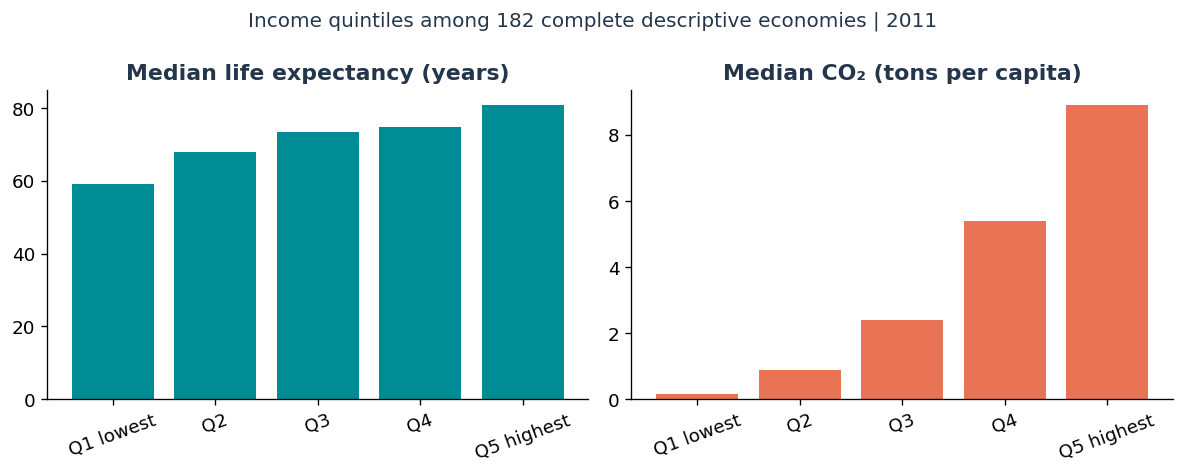

In [4]:
pair['quintile'] = pd.qcut(pair.gdp,5,labels=['Q1 lowest','Q2','Q3','Q4','Q5 highest'])
quintiles=pair.groupby('quintile',observed=True).agg(n=('life','size'),life=('life','median'),co2=('co2','median'),gdp=('gdp','median'))
print(quintiles.round(2).to_string()); quintiles.to_csv(OUT/'income_quintiles.csv')

fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,col,title,color in zip(axs,['life','co2'],['Median life expectancy (years)','Median CO₂ (tons per capita)'],[TEAL,CORAL]):
    ax.bar(quintiles.index,quintiles[col],color=color);ax.set_title(title);ax.tick_params(axis='x',rotation=20); ax.set_ylim(bottom=0)
fig.suptitle(f'Income quintiles among {len(pair)} complete descriptive economies | {YEAR}',fontsize=12)
chart('quintiles')

## Slide 4 — Longevity improved; emissions often rose
**Slide finding: +5.58 years mean longevity gain from 1990 to 2011.**

Match the same economies at both endpoints separately for each outcome.
Life expectancy uses **195 economies**; CO₂ uses **166 economies**, with emissions
rising in **70.5%**. The samples differ, so the percentages cannot be combined as
if they described the same group. No interpolation is used. Bootstrap intervals
measure sensitivity to resampling economies, not a random-world-sample guarantee.

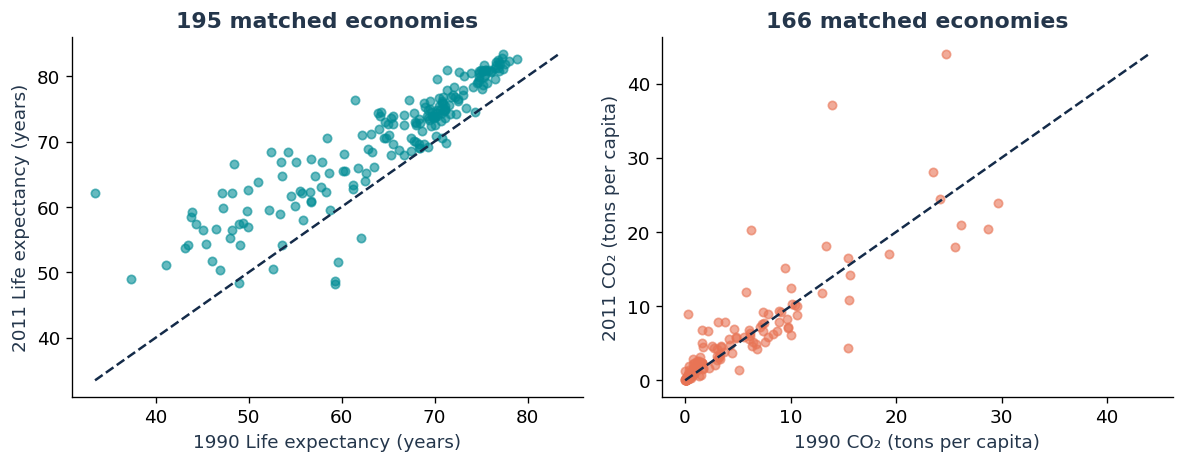

{
  "life": {
    "n": 195,
    "mean_change": 5.578393245778612,
    "median_change": 5.07448780487799,
    "ci": [
      4.973141751094436,
      6.191932789243278
    ],
    "share_increase": 0.9538461538461539
  },
  "co2": {
    "n": 166,
    "mean_change": 0.5003377592655167,
    "median_change": 0.1731883215259059,
    "ci": [
      0.02558758986819311,
      1.0229109724578291
    ],
    "share_increase": 0.7048192771084337
  }
}


In [5]:
rng=np.random.default_rng(SEED)
def boot_mean(values,B=3000):
    values=np.asarray(values);draws=rng.choice(values,(B,len(values)),replace=True).mean(axis=1)
    return np.quantile(draws,[.025,.975]).tolist()
matched={}; trend_stats={}
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,col,label in zip(axs,['life','co2'],['Life expectancy (years)','CO₂ (tons per capita)']):
    t=wide[wide.Year.isin([1990,YEAR])].pivot(index='CountryCode',columns='Year',values=col).dropna()
    t['change']=t[YEAR]-t[1990];matched[col]=t
    ci=boot_mean(t['change']);trend_stats[col]={'n':len(t),'mean_change':t.change.mean(),'median_change':t.change.median(),'ci':ci,'share_increase':(t.change>0).mean()}
    ax.scatter(t[1990],t[YEAR],s=25,color=TEAL if col=='life' else CORAL,alpha=.6)
    lim=max(t[[1990,YEAR]].max());lo=min(t[[1990,YEAR]].min());ax.plot([lo,lim],[lo,lim],ls='--',color=NAVY)
    ax.set(xlabel=f'1990 {label}',ylabel=f'{YEAR} {label}',title=f'{len(t)} matched economies')
chart('matched_change')
print(json.dumps(trend_stats,indent=2))
for col,t in matched.items():t.to_csv(OUT/f'matched_{col}.csv')

## Slide 5 — More than income improves prediction
**Slide finding: forest test MAE = 3.29 years versus 4.62 for log income, about 29% less error.**

Predict life expectancy using the same 171 complete cases for every model.
Hold out **43 economies**, train on **128**, and select settings using five folds
within training only (seed 704). Compare the mean baseline, raw/log income,
six-variable ridge and random forest. Scaling stays inside the ridge pipeline.
One row per economy prevents repeated-country leakage. Infant mortality is
excluded to avoid using a direct life-table component as a predictor.

MAE is average absolute prediction error in years; lower is better. The winner
is chosen before evaluating the test sample. One small test split limits precision.

Chosen by training CV: Random forest
Training: 128 Test: 43
                model  CV_MAE                                   parameters  test_MAE  test_RMSE  test_R2
        Random forest   2.888 {'max_features': 0.7, 'min_samples_leaf': 3}     3.290      4.945    0.675
Ridge (six variables)   3.041                         {'ridge__alpha': 10}     3.457      5.066    0.659
           Log income   3.547                                           {}     4.617      6.463    0.445
           Raw income   5.110                                           {}     7.127      9.711   -0.253
        Mean baseline   7.371                                           {}     7.077      8.862   -0.043
Selected model test MAE resampling interval: [2.262521067129424, 4.462926827952611]
MAE improvement over log-income, paired resampling interval: [0.4754893058653179, 2.187120659454121]


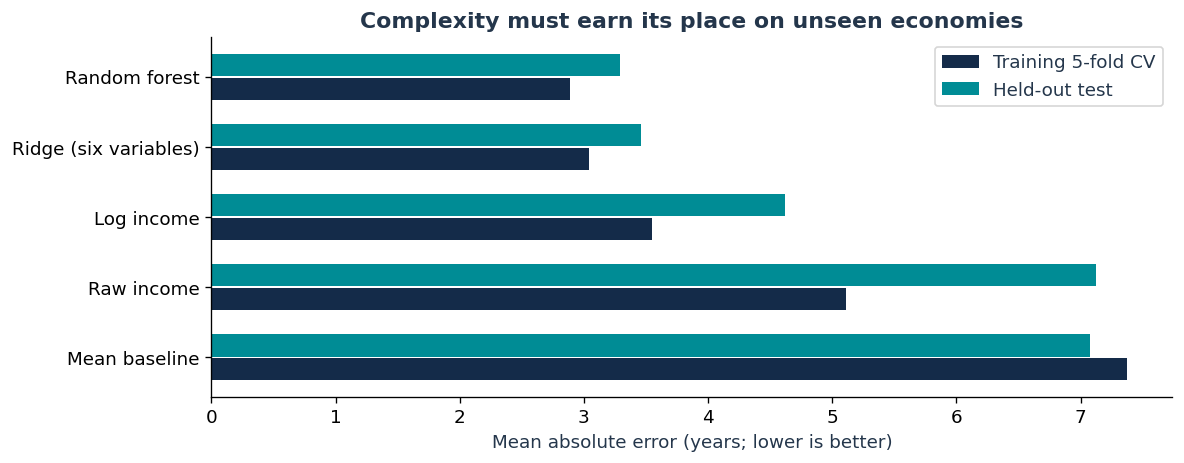

Forest error reduction versus log income: 28.8%


In [6]:
cols=['log_gdp','log_co2','sanitation','water','health','urban']
X=complete[cols]; y=complete.life
train_idx,test_idx=train_test_split(complete.index,test_size=.25,random_state=SEED)
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
specs={
 'Mean baseline':(DummyRegressor(),['log_gdp'],{}),
 'Raw income':(LinearRegression(),['gdp'],{}),
 'Log income':(LinearRegression(),['log_gdp'],{}),
 'Ridge (six variables)':(make_pipeline(StandardScaler(),Ridge()),cols,{'ridge__alpha':[.1,1,10,100]}),
 'Random forest':(RandomForestRegressor(n_estimators=250,random_state=SEED,n_jobs=1),cols,{'min_samples_leaf':[3,6,10],'max_features':[.7,1.]})}
results=[]; fitted={}
for name,(est,fs,grid) in specs.items():
    search=GridSearchCV(est,grid,cv=cv,scoring='neg_mean_absolute_error',n_jobs=1)
    search.fit(complete.loc[train_idx,fs],y.loc[train_idx])
    fitted[name]=(search.best_estimator_,fs)
    results.append({'model':name,'CV_MAE':-search.best_score_,'parameters':str(search.best_params_)})
results=pd.DataFrame(results).sort_values('CV_MAE').reset_index(drop=True)
winner=results.iloc[0]['model'] # Choice made before any test metrics.
print('Chosen by training CV:',winner)
for i,row in results.iterrows():
    est,fs=fitted[row.model];pred=est.predict(complete.loc[test_idx,fs])
    results.loc[i,'test_MAE']=mean_absolute_error(y.loc[test_idx],pred)
    results.loc[i,'test_RMSE']=np.sqrt(mean_squared_error(y.loc[test_idx],pred))
    results.loc[i,'test_R2']=r2_score(y.loc[test_idx],pred)
print('Training:',len(train_idx),'Test:',len(test_idx));print(results.round(3).to_string(index=False))
results.to_csv(OUT/'model_comparison.csv',index=False)
best,fs=fitted[winner];testX=complete.loc[test_idx,fs];pred=best.predict(testX)
errors=np.abs(y.loc[test_idx].to_numpy()-pred)
mae_ci=boot_mean(errors)
base,basefs=fitted['Log income'];basepred=base.predict(complete.loc[test_idx,basefs])
delta_ci=boot_mean(np.abs(y.loc[test_idx].to_numpy()-basepred)-errors)
print('Selected model test MAE resampling interval:',mae_ci)
print('MAE improvement over log-income, paired resampling interval:',delta_ci)
fig,ax=plt.subplots(figsize=(10,4))
order=results.sort_values('CV_MAE',ascending=False);pos=np.arange(len(order))
ax.barh(pos-.17,order.CV_MAE,height=.32,label='Training 5-fold CV',color=NAVY)
ax.barh(pos+.17,order.test_MAE,height=.32,label='Held-out test',color=TEAL)
ax.set(yticks=pos,yticklabels=order.model,xlabel='Mean absolute error (years; lower is better)',title='Complexity must earn its place on unseen economies');ax.legend()
chart('models')
test_predictions=complete.loc[test_idx,['CountryName','CountryCode','life']].copy();test_predictions['prediction']=pred;test_predictions['error']=test_predictions.life-pred
test_predictions.to_csv(OUT/'test_predictions.csv',index=False)
forest_mae = results.set_index('model').loc['Random forest', 'test_MAE']
income_mae = results.set_index('model').loc['Log income', 'test_MAE']
improvement_pct = 100 * (income_mae - forest_mae) / income_mae
print(f'Forest error reduction versus log income: {improvement_pct:.1f}%')

## Slide 6 — Sanitation is the strongest model signal
**Slide finding: shuffling sanitation adds 1.76 years to test MAE.**

Shuffle one input at a time in the held-out test sample while keeping the fitted
forest fixed. Water and income also contribute useful information. Error bars
show variability across shuffles, not confidence intervals for causal effects.
Correlated inputs can share or conceal importance; this ranking does not
estimate what an intervention would achieve.

   feature  MAE_increase  shuffle_sd
     urban         0.062       0.041
   log_co2         0.134       0.065
    health         0.287       0.093
   log_gdp         0.639       0.190
     water         0.784       0.224
sanitation         1.758       0.381


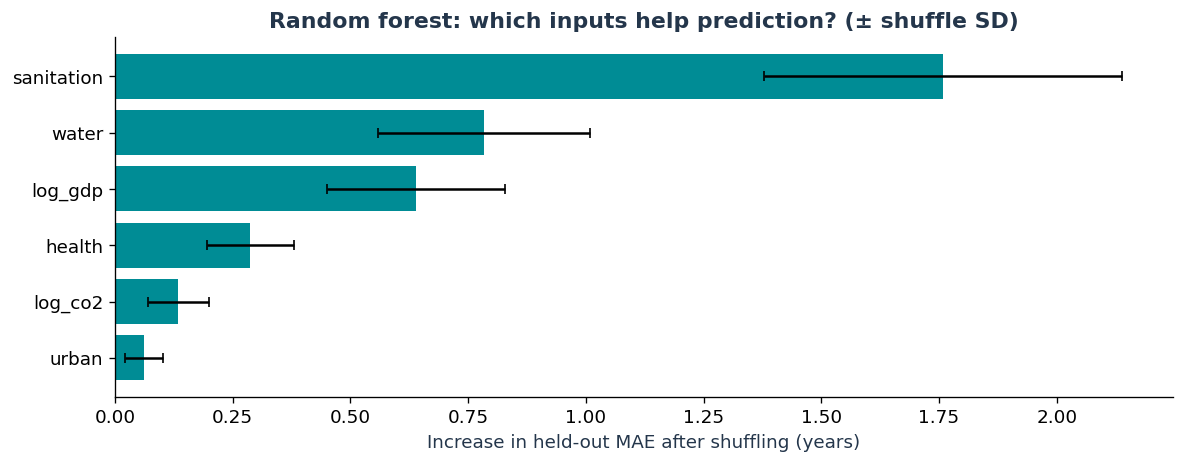

In [7]:
forest,ff=fitted['Random forest']
imp=permutation_importance(forest,complete.loc[test_idx,ff],y.loc[test_idx],n_repeats=40,scoring='neg_mean_absolute_error',random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':ff,'MAE_increase':imp.importances_mean,'shuffle_sd':imp.importances_std}).sort_values('MAE_increase')
print(importance.round(3).to_string(index=False));importance.to_csv(OUT/'permutation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4));ax.barh(importance.feature,importance.MAE_increase,xerr=importance.shuffle_sd,color=TEAL,capsize=3)
ax.axvline(0,color=NAVY,lw=1);ax.set(xlabel='Increase in held-out MAE after shuffling (years)',title='Random forest: which inputs help prediction? (± shuffle SD)');chart('importance')

## Slide 7 — One prediction, explained
**Slide finding: ridge predicts 58.5 years for Afghanistan; observed life expectancy is 59.3.**

Use the alphabetically first test economy, rather than selecting a flattering
example. This is the transparent **ridge model**, separate from the winning forest.
Its baseline is the training mean, **69.64 years**. Standardized feature
contributions add exactly to the prediction: lower sanitation, water and income
produce the largest downward contributions. These bars explain model arithmetic,
not the consequences of policy changes.

Afghanistan actual 59.32795121951221 predicted 58.5320301528747 intercept 69.63771208079268
   feature  contribution_years
sanitation              -4.374
     water              -3.431
   log_gdp              -3.070
     urban              -0.633
   log_co2               0.069
    health               0.332


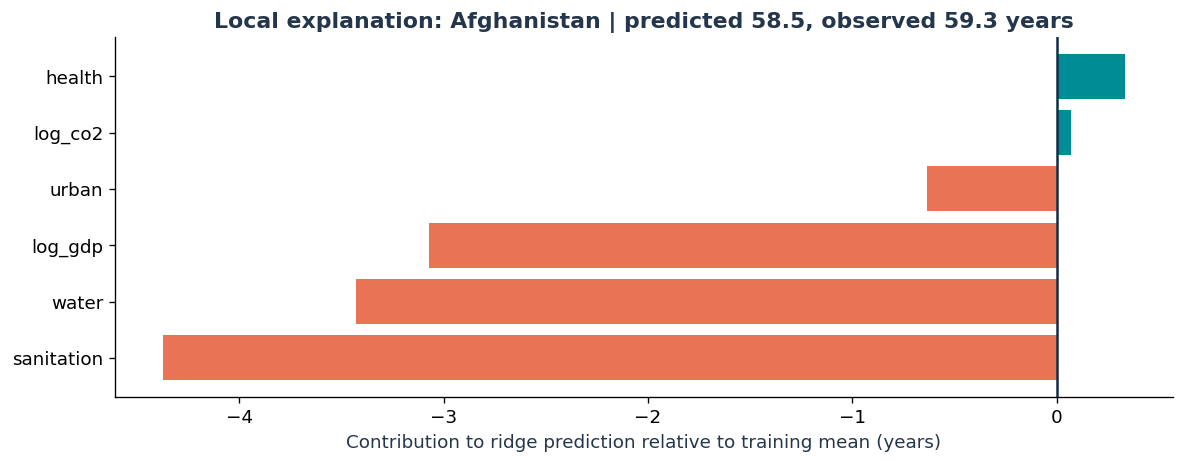

In [8]:
ridge,rf=fitted['Ridge (six variables)'];local_idx=complete.loc[test_idx].sort_values('CountryName').index[0]
z=ridge.named_steps['standardscaler'].transform(complete.loc[[local_idx],rf])[0]
contributions=z*ridge.named_steps['ridge'].coef_;intercept=ridge.named_steps['ridge'].intercept_
local_prediction=ridge.predict(complete.loc[[local_idx],rf])[0]
assert np.isclose(intercept+contributions.sum(),local_prediction)
local=pd.DataFrame({'feature':rf,'contribution_years':contributions}).sort_values('contribution_years')
local_name=complete.loc[local_idx,'CountryName'];print(local_name,'actual',complete.loc[local_idx,'life'],'predicted',local_prediction,'intercept',intercept)
print(local.round(3).to_string(index=False));local.to_csv(OUT/'local_ridge_explanation.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4));ax.barh(local.feature,local.contribution_years,color=[TEAL if v>=0 else CORAL for v in local.contribution_years]);ax.axvline(0,color=NAVY)
ax.set(xlabel='Contribution to ridge prediction relative to training mean (years)',title=f'Local explanation: {local_name} | predicted {local_prediction:.1f}, observed {complete.loc[local_idx,"life"]:.1f} years');chart('local')

## Slide 8 — Some economies broke the pattern
**Slide finding: 29 of 140 economies increased income and longevity while reducing CO₂ per person.**

Require all three indicators at both 1990 and 2011 endpoints. This common sample
differs from Slide 4's separate outcome samples. Endpoint changes do not prove
a continuous trend, a mechanism, or a reduction in total emissions.

The slide's chart answers a related, separate question: which economies have
longevity above or below income-only predictions? Use out-of-fold predictions
so each residual comes from a model that did not train on that economy. Residuals
identify research questions, not policy-quality scores.

Joint income/longevity gains with lower per-capita CO2: {'n': 140, 'success_n': 29, 'share': 0.20714285714285716, 'examples': ['Albania', 'Belgium', 'Bulgaria', 'Bahrain', 'Canada', 'Switzerland', 'Colombia', 'Denmark', 'Finland', 'France']}
Above income-only expectation:
CountryName  life     gdp  OOF_income_residual
    Vietnam 75.46 4716.98                 8.93
  Nicaragua 73.90 4223.43                 7.75
    Vanuatu 71.13 2915.24                 7.73
 Bangladesh 70.47 2579.34                 6.95
    Albania 77.16 9640.13                 6.68
Below income-only expectation:
      CountryName  life      gdp  OOF_income_residual
          Nigeria 51.74  5230.60               -15.65
     South Africa 55.30 12290.89               -17.03
           Angola 51.06  6949.02               -17.68
        Swaziland 48.66  7620.20               -20.90
Equatorial Guinea 56.45 36754.81               -21.67


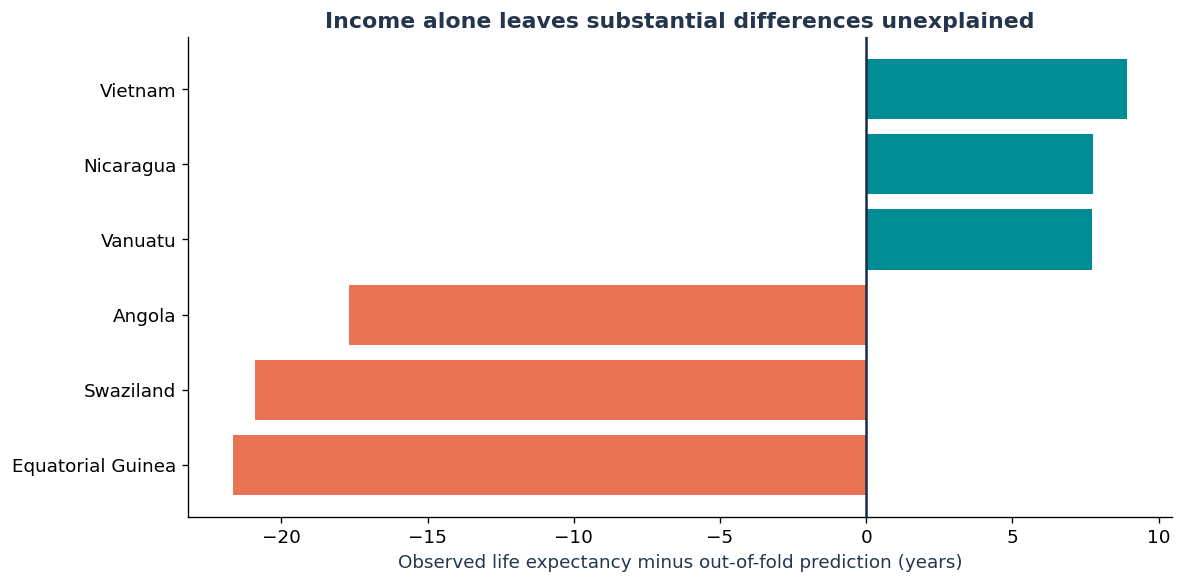

In [9]:
# Joint endpoint sample

joint = wide[wide.Year.isin([1990,YEAR])].pivot(index=['CountryCode','CountryName'],columns='Year',values=['life','gdp','co2']).dropna()
life_gain = joint[('life',YEAR)]-joint[('life',1990)]
gdp_gain = joint[('gdp',YEAR)]-joint[('gdp',1990)]
co2_gain = joint[('co2',YEAR)]-joint[('co2',1990)]
joint_success = (life_gain>0)&(gdp_gain>0)&(co2_gain<0)
joint_stats={'n':len(joint),'success_n':int(joint_success.sum()),'share':float(joint_success.mean()),'examples':joint[joint_success].reset_index().CountryName.head(10).tolist()}
print('Joint income/longevity gains with lower per-capita CO2:',joint_stats)
joint.to_csv(OUT/'joint_endpoint_changes.csv')

oof=cross_val_predict(LinearRegression(),complete[['log_gdp']],y,cv=cv)
exceptions=complete[['CountryName','life','gdp']].copy();exceptions['OOF_income_residual']=y-oof
exceptions=exceptions.sort_values('OOF_income_residual',ascending=False)
print('Above income-only expectation:');print(exceptions.head(5).round(2).to_string(index=False))
print('Below income-only expectation:');print(exceptions.tail(5).round(2).to_string(index=False))
exceptions.to_csv(OUT/'income_exceptions_oof.csv',index=False)

z = pd.concat([exceptions.head(3), exceptions.tail(3)]).sort_values('OOF_income_residual')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(z.CountryName, z.OOF_income_residual,
        color=[TEAL if value > 0 else CORAL for value in z.OOF_income_residual])
ax.axvline(0, color=NAVY)
ax.set(xlabel='Observed life expectancy minus out-of-fold prediction (years)',
       title='Income alone leaves substantial differences unexplained')
chart('exceptions')

## Slide 9 — Measure progress beyond income
**Takeaway:** Wealth tracks longevity, but development has more than one outcome.

Income alone misses important differences. Additional development indicators
improve held-out prediction, and health and carbon should be tracked separately.

- **Selection:** missingness changes the sample; complete cases may differ.
- **Uncertainty:** only 43 test economies and one split; results are historical.
- **Causality:** associations and predictive importance do not establish effects.

Check the income–longevity correlation after removing the richest 5% (about
**0.830**) and compare equal-economy versus population-weighted longevity.
Country averages hide inequalities; omitted conflict, disease, education and
institutions remain plausible explanations. Health spending share is not spending
per person, and per-capita CO₂ is not a complete environmental footprint.

In [10]:
trim=pair[pair.gdp<=pair.gdp.quantile(.95)];trim_rho=spearmanr(trim.gdp,trim.life).statistic
pop=pair.dropna(subset=['population']);weighted=np.average(pop.life,weights=pop.population)
print('Spearman full:',rho,'excluding richest 5%:',trim_rho)
print('Economy mean life:',pair.life.mean(),'population-weighted life:',weighted,'population-complete n:',len(pop))
metrics={'raw_rows':len(raw),'indicators':raw.IndicatorName.nunique(),'entities':raw.CountryCode.nunique(),'year':YEAR,'snapshot_n':len(snap),'pair_n':len(pair),'complete_n':len(complete),'train_n':len(train_idx),'test_n':len(test_idx),'rho':rho,'trim_rho':trim_rho,'quintiles':quintiles.reset_index().to_dict('records'),'trend':trend_stats,'joint':joint_stats,'winner':winner,'models':results.to_dict('records'),'mae_ci':mae_ci,'delta_ci':delta_ci,'local_name':local_name,'local_actual':complete.loc[local_idx,'life'],'local_prediction':local_prediction,'local_intercept':intercept,'exceptions_top':exceptions.head(5).to_dict('records'),'exceptions_bottom':exceptions.tail(5).to_dict('records'),'economy_mean_life':pair.life.mean(),'population_weighted_life':weighted,'source_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest()}
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2,default=float))
print('Saved charts, source checksum, samples, model predictions and audit tables to',OUT.resolve())

Spearman full: 0.8424959939490403 excluding richest 5%: 0.8296705953109671
Economy mean life: 70.31759340659342 population-weighted life: 70.76818186841737 population-complete n: 182
Saved charts, source checksum, samples, model predictions and audit tables to /Users/shomritasingha/Documents/Budt704/project_worlddata/outputs/concise_analysis


### Check agreement with the slides
The checks below compare the analysis with the rounded figures displayed in
`Wealth_Longevity_Carbon_Concise.pptx`. They fail visibly if a changed source or
software result no longer supports a slide claim. All figures are calculated
above; none are substituted for model outputs.

In [11]:
checks = {
    'Slide 1: year and sample sizes': YEAR == 2011 and len(pair) == 182 and len(complete) == 171,
    'Slide 2: rank correlation': round(float(rho), 3) == 0.842,
    'Slide 3: life expectancy medians': np.allclose(
        quintiles.life.iloc[[0, -1]], [59.2, 81.0], atol=0.05),
    'Slide 3: CO2 medians': np.allclose(
        quintiles.co2.iloc[[0, -1]], [0.16, 8.92], atol=0.005),
    'Slide 4: longevity gain and samples': round(float(trend_stats['life']['mean_change']), 2) == 5.58
        and trend_stats['life']['n'] == 195 and trend_stats['co2']['n'] == 166
        and round(100 * trend_stats['co2']['share_increase'], 1) == 70.5,
    'Slide 5: split and selected model': len(train_idx) == 128 and len(test_idx) == 43
        and winner == 'Random forest',
    'Slide 5: test MAE and reduction': round(float(forest_mae), 2) == 3.29
        and round(float(income_mae), 2) == 4.62 and round(float(improvement_pct)) == 29,
    'Slide 6: sanitation importance': importance.iloc[-1]['feature'] == 'sanitation'
        and round(float(importance.set_index('feature').loc['sanitation', 'MAE_increase']), 2) == 1.76,
    'Slide 7: local example': local_name == 'Afghanistan'
        and round(float(local_prediction), 1) == 58.5
        and round(float(complete.loc[local_idx, 'life']), 1) == 59.3,
    'Slide 8: joint sample': joint_stats['success_n'] == 29 and joint_stats['n'] == 140,
    'Slide 9: trimmed correlation': round(float(trim_rho), 3) == 0.830,
}
for label, passed in checks.items():
    print(('PASS' if passed else 'FAIL'), label)
assert all(checks.values()), 'Analysis differs from the displayed slide figures; review before using the deck.'
(OUT / 'slide_checks.json').write_text(json.dumps({k: bool(v) for k, v in checks.items()}, indent=2))
print('All nine slide sections agree with the calculated results.')

PASS Slide 1: year and sample sizes
PASS Slide 2: rank correlation
PASS Slide 3: life expectancy medians
PASS Slide 3: CO2 medians
PASS Slide 4: longevity gain and samples
PASS Slide 5: split and selected model
PASS Slide 5: test MAE and reduction
PASS Slide 6: sanitation importance
PASS Slide 7: local example
PASS Slide 8: joint sample
PASS Slide 9: trimmed correlation
All nine slide sections agree with the calculated results.
